# Random Forest — PathSnap candidate classifier

Algorithm family: ensemble (bagging of decision trees).

This notebook:
1. Loads the shared candidate table (`data/processed/`). It uses the same features, labels and trip-level folds as every other model.
2. Runs 5-fold group cross-validation, grouped by trip, on the 80 training trips.
3. Refits on all training rows and evaluates on the 10 student-testing trips.
4. Saves `metrics.json`, `cv_folds.csv`, `model.joblib` and the plots into `models/random_forest/`.

Run the cells top to bottom. Runtime is about 5–10 min on a 4-core laptop with the settings below.

In [1]:
import os, sys, json, time
from pathlib import Path
# find the repo root (the folder that contains config.yaml) and make `pathsnap` importable
ROOT = Path.cwd()
while not (ROOT / "config.yaml").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Open this notebook from inside the pathsnap-ml-hackathon repo")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathsnap.dataset import FEATURES
from pathsnap import modeling as M
print("repo root:", ROOT)

repo root: C:\3rd year material\ML\Hackathon\pathsnap_preprocessing


## Settings
The rows a model is fitted on are subsampled inside each fold to keep runtime and model size manageable. Every trip is kept. Validation folds and the student-test set are always used in full.

In [2]:
ROWS_PER_FOLD = 60_000          # 5 folds -> ~300k training rows (None = all ~1.48M rows)
PARAMS = dict(
    n_estimators=100,
    max_depth=20,                # limits overfitting and model file size
    min_samples_leaf=5,
    max_features="sqrt",
    n_jobs=-1,
    random_state=M.SEED,
)
OUT = ROOT / "models" / "random_forest"
OUT.mkdir(parents=True, exist_ok=True)

In [3]:
tr, te, tr_pts, te_pts = M.load_data()
print(f"labelled train rows: {len(tr):,}  (positive rate {tr.label.mean():.3f}, trips {tr.trip_id.nunique()})")
print(f"rows used for FITTING: up to {ROWS_PER_FOLD or 'all'} per fold; validation always uses full folds")
print(f"student-test rows: {len(te):,}  (trips {te.trip_id.nunique()})")
print(f"features ({len(FEATURES)}):", FEATURES)

labelled train rows: 1,479,905  (positive rate 0.125, trips 80)
rows used for FITTING: up to 60000 per fold; validation always uses full folds
student-test rows: 169,408  (trips 10)
features (37): ['dist', 'dist_rel', 'dist_ratio', 'rank', 'n_cand', 'dist_min', 'proj_t', 'at_endpoint', 'arc_len', 'log_arc_len', 'heading_ok', 'heading_diff', 'heading_diff_undirected', 'cos_heading', 'speed', 'turn', 'dt_prev', 'dt_next', 'step_prev', 'out_deg_to', 'in_deg_from', 'has_reverse', 'ctx_dist_prev1', 'ctx_dist_next1', 'ctx_dist_prev2', 'ctx_dist_next2', 'ctx_dist_mean', 'ctx_cand_prev', 'ctx_cand_next', 'link_prev_nearest', 'link_next_nearest', 'overshoot_m', 'progress_prev', 'progress_next', 'progress_2s', 'straightness', 'speed_window']


## Model
Optimisation objective: each tree minimises Gini impurity. Rows are weighted by `trip_weight` so that every trip contributes equally. No feature scaling is needed for trees.

In [4]:
from sklearn.ensemble import RandomForestClassifier

def make_model():
    return RandomForestClassifier(**PARAMS)

def fit_fn(model, df):
    return model.fit(df[FEATURES], df["label"], sample_weight=df["trip_weight"].values)

## 5-fold group cross-validation (trip-level)

In [5]:
cv = M.cross_validate(make_model, fit_fn, tr, tr_pts, ROWS_PER_FOLD)
cv[["fold", "top1_accuracy", "train_top1", "f1_macro", "precision_macro", "recall_macro", "log_loss", "fit_seconds"]].round(4)

fold 0: val top1=0.8934  train top1=0.9373  f1_macro=0.9371  log_loss=0.0895  (21s)


fold 1: val top1=0.8411  train top1=0.9218  f1_macro=0.9119  log_loss=0.0887  (20s)


fold 2: val top1=0.8861  train top1=0.9067  f1_macro=0.9332  log_loss=0.0618  (19s)


fold 3: val top1=0.9233  train top1=0.8666  f1_macro=0.9525  log_loss=0.0537  (19s)


fold 4: val top1=0.8573  train top1=0.9098  f1_macro=0.9099  log_loss=0.0894  (19s)


,fold,top1_accuracy,train_top1,f1_macro,precision_macro,recall_macro,log_loss,fit_seconds
0,0,0.8934,0.9373,0.9371,0.9390,0.9352,0.0895,20.9737
1,1,0.8411,0.9218,0.9119,0.9308,0.8951,0.0887,19.9830
2,2,0.8861,0.9067,0.9332,0.9453,0.9220,0.0618,18.8770
3,3,0.9233,0.8666,0.9525,0.9590,0.9462,0.0537,18.7251
4,4,0.8573,0.9098,0.9099,0.9384,0.8859,0.0894,19.2859


CV Top-1     : 0.8802 ± 0.0321
CV macro F1  : 0.9289 ± 0.0180
CV log loss  : 0.0766
train Top-1  : 0.9085   (gap to CV = overfitting evidence)


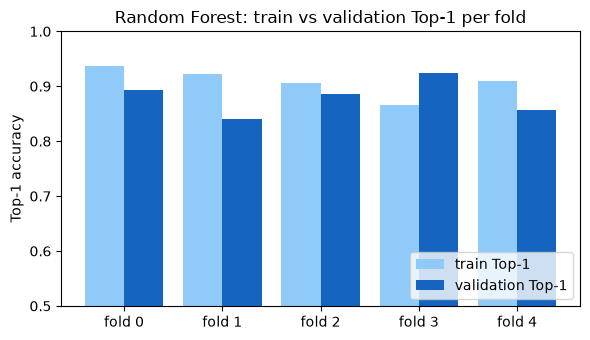

In [6]:
print("CV Top-1     : %.4f ± %.4f" % (cv.top1_accuracy.mean(), cv.top1_accuracy.std()))
print("CV macro F1  : %.4f ± %.4f" % (cv.f1_macro.mean(), cv.f1_macro.std()))
print("CV log loss  : %.4f" % cv.log_loss.mean())
print("train Top-1  : %.4f   (gap to CV = overfitting evidence)" % cv.train_top1.mean())
M.plot_cv_folds(cv, "Random Forest: train vs validation Top-1 per fold", OUT / "cv_folds.png")

## Final fit on all training rows → student-testing trips

In [7]:
model, scores, test, train_s, infer_ms = M.fit_and_test(make_model, fit_fn, tr, te, te_pts, ROWS_PER_FOLD)
print(f"train time: {train_s:.1f}s   inference: {infer_ms:.3f} ms per 1000 candidate rows")
pd.Series({k: v for k, v in test.items() if k != "confusion_matrix"}).to_frame("student_test")

train time: 25.5s   inference: 2.704 ms per 1000 candidate rows


,student_test
top1_accuracy,0.888465
top1_given_ref_in_candidates,0.888744
candidate_miss_rate,0.000314
accuracy,0.974570
precision_macro,0.944970
recall_macro,0.925871
f1_macro,0.935139
precision_pos,0.907272
recall_pos,0.862969
f1_pos,0.884566


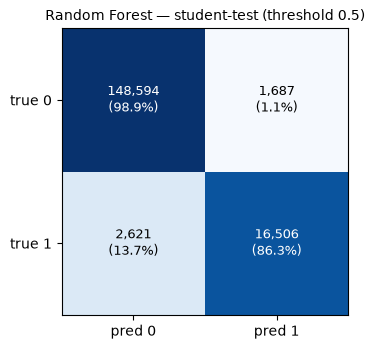

In [8]:
M.plot_confusion(test["confusion_matrix"], "Random Forest — student-test (threshold 0.5)", OUT / "confusion_matrix.png")

## Feature importance (impurity-based)

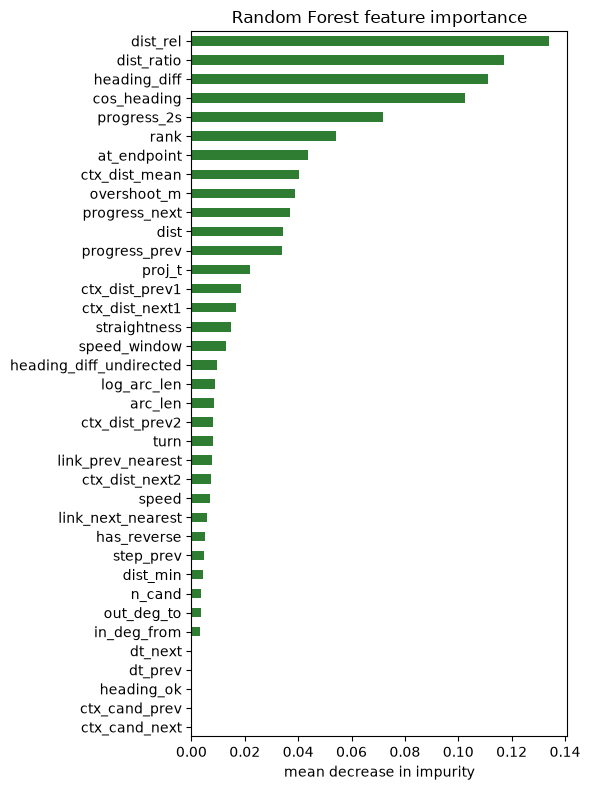

In [9]:
imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6, 8))
imp.plot.barh(ax=ax, color="#2e7d32")
ax.set(title="Random Forest feature importance", xlabel="mean decrease in impurity")
plt.tight_layout(); plt.savefig(OUT / "feature_importance.png", dpi=130); plt.show()
imp.sort_values(ascending=False).to_csv(OUT / "feature_importance.csv")

## Save results

In [10]:
res = M.save_run(OUT, "random_forest", "Ensemble (bagging)", PARAMS, cv, test, train_s, infer_ms,
                 model=model, rows_per_fold=ROWS_PER_FOLD)
print(json.dumps({k: v for k, v in res.items() if k != "student_test"}, indent=1, default=str))

saved C:\3rd year material\ML\Hackathon\pathsnap_preprocessing\models\random_forest\model.joblib (10.1 MB)
{
 "model": "random_forest",
 "algorithm_family": "Ensemble (bagging)",
 "config": {
  "n_estimators": 100,
  "max_depth": 20,
  "min_samples_leaf": 5,
  "max_features": "sqrt",
  "n_jobs": -1,
  "random_state": 42
 },
 "seed": 42,
 "train_rows_per_fold": 60000,
 "cv_top1_mean": 0.880230568435677,
 "cv_top1_std": 0.032082725687669254,
 "cv_f1_macro_mean": 0.9289105300984929,
 "cv_f1_macro_std": 0.01799229710073991,
 "cv_log_loss_mean": 0.07662960396703164,
 "cv_train_top1_mean": 0.9084701383782653,
 "train_seconds": 25.479904399999214,
 "inference_ms_per_1000_rows": 2.7037040753695423
}


## Notes for the report (fill in from YOUR results above)
- Why this algorithm suits PathSnap, and its strengths and limitations as observed here.
- Hyperparameters and initial values: see `PARAMS`. Objective: Gini impurity per tree.
- Student-test Top-1, macro F1 and log loss: see the table above.
- Over- or underfitting: compare `train_top1` with the validation Top-1, and look at the variation across folds.